<h1 style="font-size: 180%">Single-mixed refrigerant (SMR) natural gas liquefaction process simulation optimization <a href="https://doi.org/10.1016/j.ces.2021.116699" title="SMR optimization paper">[1]</a> </h1>

<hr>

<h2 style="font-size: 150%">SMR process description</h2>

The single-mixed refrigerant natural gas liquefaction process consists of using a multi-component refrigerant operating in a refrigeration cycle to produce heat sink to cool down and liquefy the natural gas stream, as illustrated in the figure below. The refrigeration cycle includes a four-stage compression system with intermediate cooling and phase separation for possible condensate. The liquid phase is compressed in pumps and the vapor phase in the compressors. No phase mixing is considered, which means that the refrigerant heavy condensate is mixed together and goes through the hot pass in the multi-stream heat exchanger separately from the light vapor phase. Then, the streams are mixed back together in the cold pass inside the cryogenic heat exchanger as they vaporize.

<br/>
<br/>
<img src="pfd_smr.png" alt="process flow diagram image" style="height: 400px"/>
<br/>
<br/>

<h2 style="font-size: 150%"> SMR process simulation</h2>

The described single-mixed refrigerant natural gas liquefaction process is rather difficult to model and simulate mainly because it involves Pinch-like calculations in each multi-stream heat exchangers (MSHE) considering phase change, cryogenic conditions, and non-ideal mixtures. In other words, these heat exchangers are discretized in temperature segments, where vapor-liquid equilibrium calculations are performed to determine the temperature of every stream and, therefore, the temperature profiles in these operation units. For the sake of process feasibility considering the Second Law of Thermodynamics, the temperatures of hot streams have to be effectively higher than the cold ones throughout the heat exchangers.
For rigorous calculations, this process is modeled and simulated in DWSIM v7.0 using Peng-Robinson equation of state, which is appropriate for hydrocarbons mixtures, such as the natural gas and the refrigerant mixtures. The minimum internal temperature approach is calculated using the Python Script in DWSIM. See the simulation `SMR_2exp_phaseSep_MSHE_MITApy.dwxmz` for more details.

<br />
<br />
<img src="pfd_smr_dwsim.png" alt="process flow diagram image" style="height: 400px"/>
<br />
<br />

<h2 style="font-size: 150%">SMR process optimization problem</h2>

Knowing that the work consumption is the most relevant spending in the natural gas liquefaction process, then the design problem is to find $\textbf{x}^*\in \mathbb{R}^n$ that minimizes the following optimization problem

$$ \min*{\textbf{x}\in \mathcal{D}}\ \ f(\textbf{x})=\frac{\sum*{p\in PM}{W*p(\textbf{x})}}{\dot{m}*{NG}} $$
$$ \text{s.t.} \ \ g(\textbf{x})=3 - MITA(\textbf{x})\le 0$$
$$ \mathcal{D}=[\textbf{x}^{lb},\ \textbf{x}^{ub}], $$

in which, for a given $\textbf{x}$, $W_p(\textbf{x})$ is the work consumption of the pressure manipulator unit $p$ in the set of compressors and pumps $PM$, $MITA(\textbf{x})$ is the minimum internal temperature approach in the MSHEs, $\mathcal{D}$ is a box constraint for the decision variables bounded by $\textbf{x}^{lb}$ and $\textbf{x}^{ub}$, and $\dot{m}_{LNG}$ is the mass flow rate of the natural gas stream. Therefore, the objective function $f$ in this optimization problem is the specific work consumed in the refrigeration cycle with respect to the mass flow rate of liquefied natural gas (LNG). Notice that the value of $W_p(\textbf{x})$ as well as $MITA(\textbf{x})$ are obtained in the black-box chemical process simulator, and so are $f(\textbf{x})$ and $g(\textbf{x})$. Then, $f(\textbf{x})$ and $g(\textbf{x})$ are known only at sampled points and make the optimization problem equivalent to equation above.


In [1]:
import os
from pathlib import Path
from pprint import pprint

import numpy as np
from dotenv import load_dotenv

from dwsimopt.solve_sim_opt import OptimiSim

load_dotenv(override=True)

dir_path = str(Path(os.getcwd()).parent.absolute())
path2dwsim = os.getenv("PATH2DWSIM") or ""

In [2]:
# Loading DWSIM simulation into Python (Simulation object)
sim_smr = OptimiSim(
    path2sim=os.path.join(dir_path, "SMR_LNG/SMR.dwxmz"),
    path2dwsim=path2dwsim,
    savepath=os.path.join(dir_path, "SMR_LNG/SMR2.dwxmz"),
    init_dwsim=True,
)

  [skip] Microsoft.ServiceBus.dll not found at C:/Users/s1375717/AppData/Local/DWSIM/Microsoft.ServiceBus.dll
  [skip] OxyPlot not found at C:/Users/s1375717/AppData/Local/DWSIM/OxyPlot
DWSIM references added.
Simulation was loaded successfully


In [3]:
from dwsimopt.py2dwsim import assign_pddx, create_pddx

# Assign DoF:
create_pddx(["MR-1", "CompoundMassFlow", "Nitrogen", "kg/s"], sim_smr, element="dof")
create_pddx(["MR-1", "CompoundMassFlow", "Methane", "kg/s"], sim_smr, element="dof")
create_pddx(["MR-1", "CompoundMassFlow", "Ethane", "kg/s"], sim_smr, element="dof")
create_pddx(["MR-1", "CompoundMassFlow", "Propane", "kg/s"], sim_smr, element="dof")
create_pddx(["MR-1", "CompoundMassFlow", "Isopentane", "Pa"], sim_smr, element="dof")
create_pddx(["VALV-01", "OutletPressure", "Mixture", "Pa"], sim_smr, element="dof")
create_pddx(["COMP-4", "OutletPressure", "Mixture", "Pa"], sim_smr, element="dof")
create_pddx(["COOL-08", "OutletTemperature", "Mixture", "K"], sim_smr, element="dof")

# Assign F
create_pddx(["Sum_W", "EnergyFlow", "Mixture", "kW"], sim_smr, element="fobj")

# adding constraints (g_i <= 0):
g1 = create_pddx(
    ["MITA1-Calc", "OutputVariable", "mita", "°C"], sim_smr, element="constraint", assign=False
)
assign_pddx(
    lambda: 3 - g1[0](),
    ["MITA1-Calc", "OutputVariable", "mita", "°C"],
    sim_smr,
    element="constraint",
)
g2 = create_pddx(
    ["MITA2-Calc", "OutputVariable", "mita", "°C"], sim_smr, element="constraint", assign=False
)
assign_pddx(
    lambda: 3 - g2[0](),
    ["MITA2-Calc", "OutputVariable", "mita", "°C"],
    sim_smr,
    element="constraint",
)
# assign_pddx( lambda: 3 - min(g2[0](),g1[0]()), ["MITA_Overall", "OutputVariable", 'mita', "°C"], sim_smr, element="constraint" )


pprint(vars(sim_smr))

Added dof pddx for CompoundMassFlow of Nitrogen from MR-1 in kg/s
Added dof pddx for CompoundMassFlow of Methane from MR-1 in kg/s
Added dof pddx for CompoundMassFlow of Ethane from MR-1 in kg/s
Added dof pddx for CompoundMassFlow of Propane from MR-1 in kg/s
Added dof pddx for CompoundMassFlow of Isopentane from MR-1 in Pa
Added dof pddx for OutletPressure of Mixture from VALV-01 in Pa
Added dof pddx for OutletPressure of Mixture from COMP-4 in Pa
Added dof pddx for OutletTemperature of Mixture from COOL-08 in K
Added fobj pddx for EnergyFlow of Mixture from Sum_W in kW
Created getter pddx for OutputVariable of mita from MITA1-Calc in °C
Added constraint pddx for OutputVariable of mita from MITA1-Calc in °C
Created getter pddx for OutputVariable of mita from MITA2-Calc in °C
Added constraint pddx for OutputVariable of mita from MITA2-Calc in °C
{'_refs_added': True,
 'dof': array([[<function _to_dwsim.<locals>.<lambda> at 0x00000189CF8E0680>,
        'MR-1', 'CompoundMassFlow', 'Nitro

In [6]:
# Setup for optimization
# Initial guess of optimization
x0 = np.array(
    [0.25 / 3600, 0.70 / 3600, 1.0 / 3600, 1.10 / 3600, 1.80 / 3600, 2.50e5, 50.0e5, -60 + 273.15]
)

# decision variables bounds
bounds = np.array([0.75 * np.asarray(x0), 1.25 * np.asarray(x0)])  # 50 % around base case
bounds[0][-1] = 153  # precool temperature low limit manually
bounds[1][-1] = 253  # precool temperature upper limit manually

xlo = bounds[0]
xup = bounds[1]

test_at_x0 = True
if test_at_x0:
    # Testing for simulation at x0
    sim_smr.calculate_optProblem(1.0 * x0)
    print(sim_smr.x_val, sim_smr.f_val, sim_smr.g_val)

    # Test saving simulation at x0 in 'savepath'
    sim_smr.interface.SaveFlowsheet2(sim_smr.flowsheet, sim_smr.savepath)

    # Inspecting simulation object
    pprint(vars(sim_smr))

f = [0.38996332], g = [-1.78267764 -3.47896172] at x = [6.94444444e-05 1.94444444e-04 2.77777778e-04 3.05555556e-04
 5.00000000e-04 2.50000000e+05 5.00000000e+06 2.13150000e+02]
[6.94444444e-05 1.94444444e-04 2.77777778e-04 3.05555556e-04
 5.00000000e-04 2.50000000e+05 5.00000000e+06 2.13150000e+02] [0.38996332] [-1.78267764 -3.47896172]
{'_refs_added': True,
 'dof': array([[<function _to_dwsim.<locals>.<lambda> at 0x00000189CF8E0680>,
        'MR-1', 'CompoundMassFlow', 'Nitrogen', 'kg/s'],
       [<function _to_dwsim.<locals>.<lambda> at 0x00000189CF8E07C0>,
        'MR-1', 'CompoundMassFlow', 'Methane', 'kg/s'],
       [<function _to_dwsim.<locals>.<lambda> at 0x00000189CF8E0540>,
        'MR-1', 'CompoundMassFlow', 'Ethane', 'kg/s'],
       [<function _to_dwsim.<locals>.<lambda> at 0x00000189CF8E0400>,
        'MR-1', 'CompoundMassFlow', 'Propane', 'kg/s'],
       [<function _to_dwsim.<locals>.<lambda> at 0x00000189CF8E05E0>,
        'MR-1', 'CompoundMassFlow', 'Isopentane', 'Pa'],

c:\Users\s1375717\Documents\dwsimopt\.venv\Lib\site-packages\sko\PSO.py:33: SyntaxWarning: invalid escape sequence '\h'
  + c_{g}r_{2j}(t)[\hat{y}_{j}(t) − x_{ij}(t)]


Starting PSO optimization
Iter: 0, Best fit: [4579.98301076] at [7.13446767e-05 1.45833333e-04 3.47222222e-04 3.53344642e-04
 3.87738173e-04 2.83133611e+05 3.79653736e+06 2.53000000e+02]
Iter: 1, Best fit: [4579.98301076] at [7.13446767e-05 1.45833333e-04 3.47222222e-04 3.53344642e-04
 3.87738173e-04 2.83133611e+05 3.79653736e+06 2.53000000e+02]
Iter: 2, Best fit: [4579.98301076] at [7.13446767e-05 1.45833333e-04 3.47222222e-04 3.53344642e-04
 3.87738173e-04 2.83133611e+05 3.79653736e+06 2.53000000e+02]


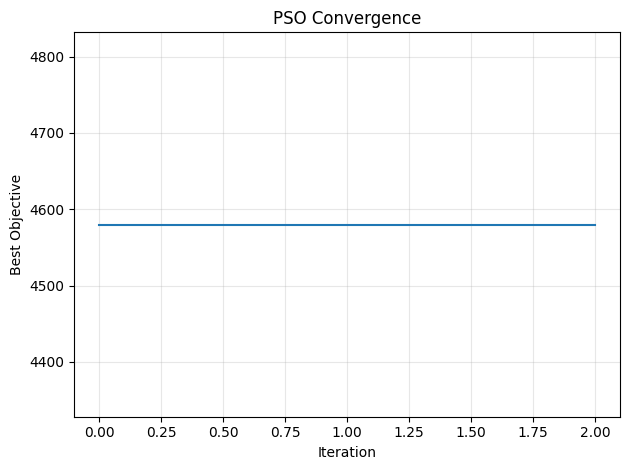

PSO finished with x* = [7.13446767e-05 1.45833333e-04 3.47222222e-04 3.53344642e-04
 3.87738173e-04 2.83133611e+05 3.79653736e+06 2.53000000e+02]
  fobj = 0.34006620575315477
  g_0 = 4.579642944549676
  g_1 = -2.00190333272198


In [7]:
# Global optimization with PSO
sim_smr.verbose = False
results_PSO = sim_smr.PSO(x0, xlo, xup, pop=1, max_ite=3)

Starting GA optimization


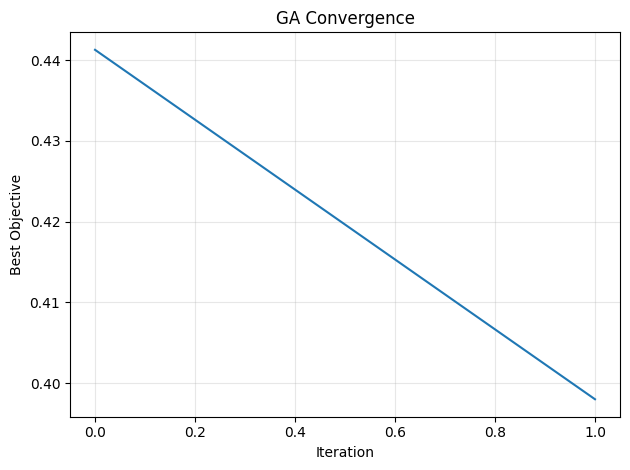

GA finished with x* = [7.63413242e-05 1.55812154e-04 3.29241980e-04 3.69256500e-04
 5.57112332e-04 2.25295862e+05 4.41733411e+06 1.85499661e+02]
  fobj = 0.39800737290098737
  g_0 = -0.6275792157764783
  g_1 = -4.367837610772398


In [8]:
# Global optimization with GA
sim_smr.verbose = False
results_GA = sim_smr.GA(x0, xlo, xup, pop=2, max_ite=2, prob_mut=0.2)

Starting DE optimization


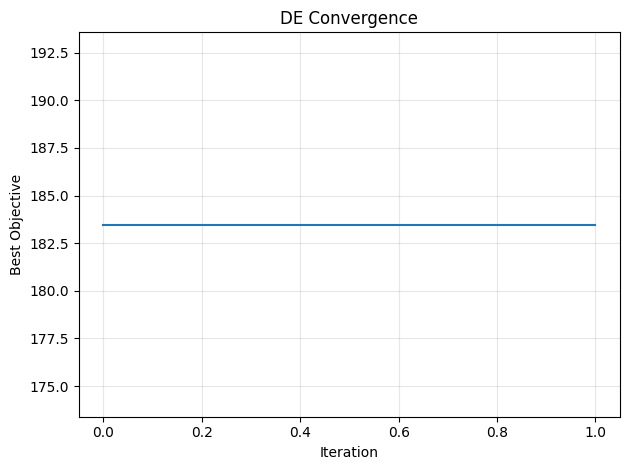

DE finished with x* = [7.67058068e-05 1.51117931e-04 3.17078698e-04 3.18228828e-04
 3.86591253e-04 2.74917084e+05 4.90211767e+06 2.09496445e+02]
  fobj = 0.35584900764108957
  g_0 = 0.18312434448259296
  g_1 = -3.281376464981008


In [9]:
# Global optimization with DE
sim_smr.verbose = False
results_DE = sim_smr.DE(x0, xlo, xup, pop=2, max_ite=2)

In [10]:
# Global optimization with AFSA
sim_smr.verbose = False
results_AFSA = sim_smr.AFSA(
    x0, pop=1, max_ite=2, max_try_num=2, step=0.1, visual=0.3, q=0.98, delta=0.1
)

Starting AFSA optimization
